# Explore a PDE inverse problem
Run All to inspect one square-domain T1 case, its equation graph, source/initial fields and sparse noisy observations. No optimizer updates or full verification suite runs. D is an exact Bayesian reference; loading a neural model is optional. Routine training is in **02_train.ipynb**.

In [1]:
from pathlib import Path
import sys, subprocess, importlib.util
PROJECT_DIR = None  # Colab: "/content/PDEep" after uploading/cloning the complete project.
INSTALL_PROJECT = False  # Colab first use: True. Local editable install: False.
if PROJECT_DIR is not None:
    project = Path(PROJECT_DIR).expanduser().resolve()
    if not (project / "pyproject.toml").is_file():
        raise RuntimeError("PROJECT_DIR must contain the complete PDEep project")
    if INSTALL_PROJECT:
        subprocess.run([sys.executable, "-m", "pip", "install", "-e", str(project)], check=True)
import pdeep, json
ROOT = Path(pdeep.__file__).resolve().parents[2]
if PROJECT_DIR is not None and ROOT != project:
    raise RuntimeError("Kernel imports another PDEep checkout; install this project and restart the kernel")
from IPython.display import display, Markdown
from pdeep.notebook_workflows import initialize
print("Project:", ROOT)


Project: /Users/nicolasackermann/Documents/ChatGPT/PDEep


In [2]:
PDE = "wave"  # poisson, heat, wave
CASE_ID = 0  # fixed validation case; never used for training calibration
DEVICE = "auto"
MODEL_ARCHITECTURE = "B1"
MODEL_CHECKPOINT = None  # explicit v2 inference export or training-checkpoint manifest
ALLOW_PARTIAL = False  # must be explicit to inspect smoke/bounded models
USE_D_BASELINE = True  # exact classical posterior when no neural model is selected
PHYSICAL_TIME = .2


In [3]:
from pdeep.runtime import capabilities
from pdeep.notebook_workflows import physical_example
CONTEXT = initialize(ROOT, device=DEVICE)
CASE, SENSORS = physical_example(CONTEXT, PDE, CASE_ID)
from pdeep.reference import canonical_spec
SPEC = canonical_spec(PDE)
print(CONTEXT.device_message)
print("Capabilities:", [(c.device,c.available,c.supported_dtypes) for c in capabilities()])
print("Case:", CASE.key.physical_id, "| spec:", SPEC.identity[:12], "| source:", CONTEXT.source_id[:12])
print("Training-only normalizer:", CONTEXT.normalizers.identity)


DEVICE='auto' selected mps/float32: first available: CUDA, MPS, CPU. References and B/D physics stay CPU float64. No runtime fallback.
Capabilities: [('cpu', True, ('float32', 'float64')), ('mps', True, ('float32',)), ('cuda', False, ('float32', 'float64'))]
Case: wave/12000 | spec: b5f82c638677 | source: ec0aa920b835
Training-only normalizer: b08242e6946c4612b24523bf27dc087f2f4e38d0de758555d1775b8b0bc377a2


The supported domain is the unit square with homogeneous Dirichlet conditions. Irregular domains and scalar-unknown T2 are future work. Nine lexicographically ordered sine modes define the unknown source/initial inputs; wave has18 coefficients for displacement and velocity.

In [4]:
from pdeep.benchmarks import EQUATIONS
from pdeep.graph import graph_table
from IPython.display import Math
display(Math(EQUATIONS[PDE]))
rows=graph_table(SPEC.graph)
display(Markdown("| "+" | ".join(rows[0])+" |\n|"+"---|"*len(rows[0])+"\n"+"\n".join("| "+" | ".join(str(v) for v in row.values())+" |" for row in rows)))


<IPython.core.display.Math object>

| id | op | quantity | shape | units | status | derivative | operands |
|---|---|---|---|---|---|---|---|
| 13e27917b5 | FIELD | solution.u | () | (0, 0, 0) | unknown | None | [] |
| 279bbf29bf | POWER | None | () | (0, 0, 0) | None | None | ['e0e86033b2', 'ce36f41980'] |
| 27a9681286 | LAPLACIAN | solution.u | () | (0, 0, 0) | None | ('space', 2) | ['13e27917b5'] |
| 339cd4a0ea | MULTIPLY | None | () | (0, 0, 0) | None | None | ['279bbf29bf', '27a9681286'] |
| 694867ce18 | ADD | None | () | (0, 0, 0) | None | None | ['7641903c51', 'f1effa8a5c'] |
| 6cd663e15a | EQUATION | None | () | (0, 0, 0) | None | None | ['c0e9e20078'] |
| 6ce404275c | EQUATION | None | () | (0, 0, 0) | None | None | ['694867ce18'] |
| 7641903c51 | TIME_D1 | solution.v | () | (0, 0, 0) | None | ('physical_time', 1) | ['d8e5cc9218'] |
| 7cdbfbd82d | NEG | solution.v | () | (0, 0, 0) | None | None | ['d8e5cc9218'] |
| c0e9e20078 | ADD | None | () | (0, 0, 0) | None | None | ['7cdbfbd82d', 'df273e6983'] |
| ce36f41980 | CONSTANT | None | () | (0, 0, 0) | None | None | [] |
| d8e5cc9218 | FIELD | solution.v | () | (0, 0, 0) | unknown | None | [] |
| df273e6983 | TIME_D1 | solution.u | () | (0, 0, 0) | None | ('physical_time', 1) | ['13e27917b5'] |
| e0e86033b2 | PARAMETER | physics.speed | () | (0, 0, 0) | known | None | [] |
| f1effa8a5c | NEG | None | () | (0, 0, 0) | None | None | ['339cd4a0ea'] |

Matplotlib is building the font cache; this may take a moment.


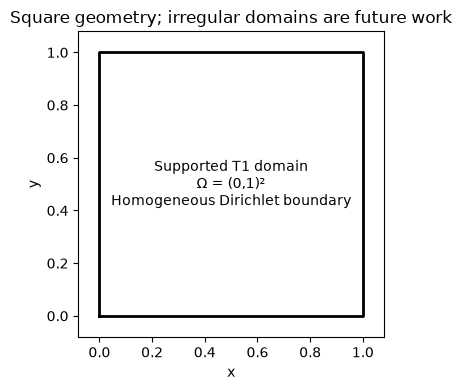

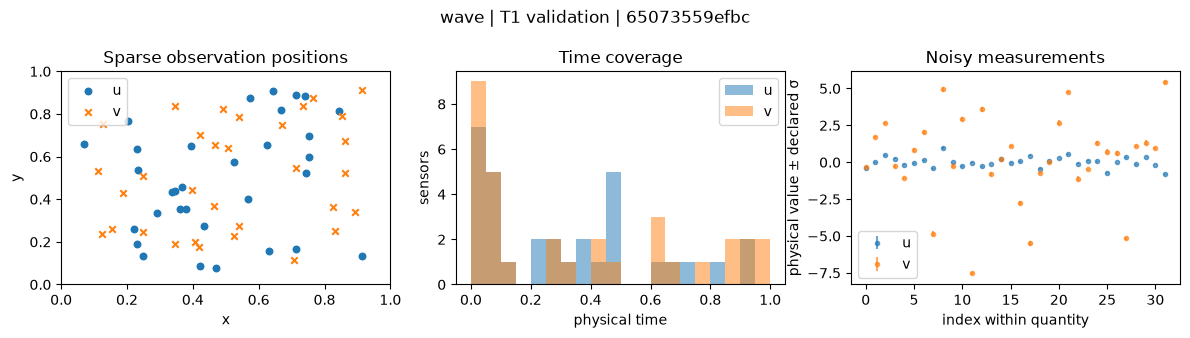

In [5]:
from pdeep.workflow_plotting import plot_geometry,plot_sensors,plot_reference,plot_source_initial
import matplotlib.pyplot as plt
display(plot_geometry()); plt.close("all")
display(plot_sensors(SENSORS,PDE)); plt.close("all")


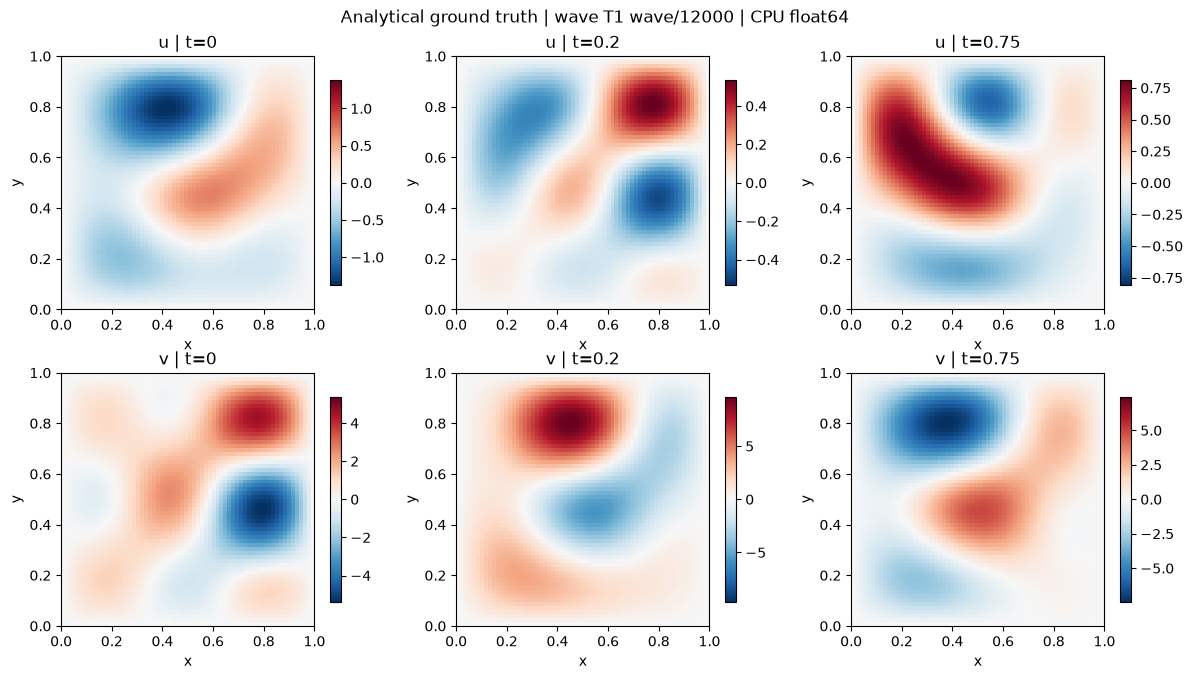

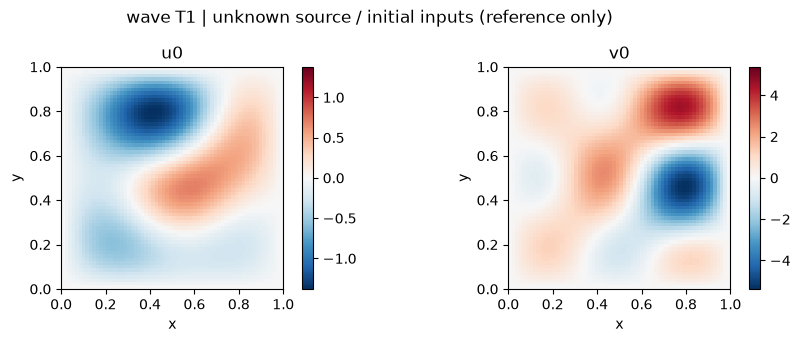

Direct CPU float64 reference evaluation at continuous physical time; no stored-frame interpolation.


In [6]:
display(plot_reference(CASE)); plt.close("all")
display(plot_source_initial(CASE)); plt.close("all")
print("Direct CPU float64 reference evaluation at continuous physical time; no stored-frame interpolation.")


## Optional reconstruction
Set `MODEL_CHECKPOINT` and `MODEL_ARCHITECTURE` to inspect your own model. Missing or incompatible paths fail explicitly. A smoke/bounded checkpoint is never treated as a trained research model. With no model selected, `USE_D_BASELINE=True` explicitly requests D's posterior mean.

In [7]:
from pdeep.notebook_workflows import exploration_method
METHOD = None
if MODEL_CHECKPOINT is not None:
    METHOD=exploration_method(CONTEXT,architecture=MODEL_ARCHITECTURE,checkpoint=MODEL_CHECKPOINT,allow_partial=ALLOW_PARTIAL)
elif USE_D_BASELINE:
    METHOD=exploration_method(CONTEXT,architecture="D")
print("Selected reconstruction:", "none" if METHOD is None else (METHOD.name,METHOD.status,METHOD.training.get("successful_updates",0)))


Selected reconstruction: ('D', 'exact; no training', 0)


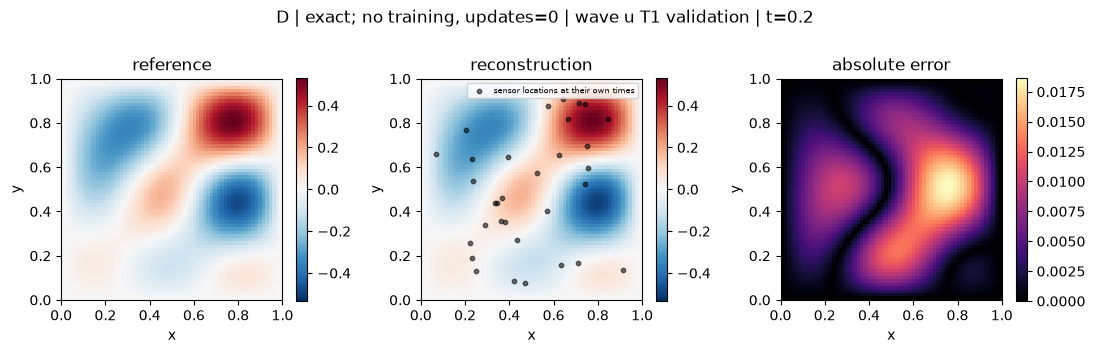

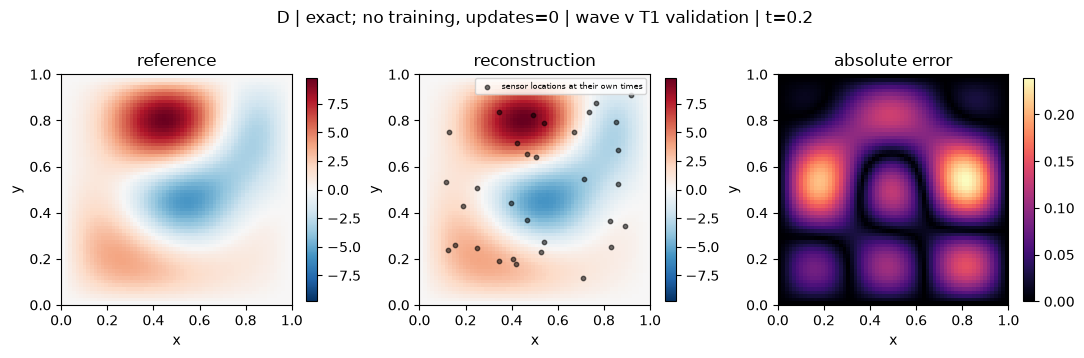

Physical and fixed-training-RMS errors: {'u': {'physical_MSE': 4.793118289271181e-05, 'physical_RMSE': 0.006923235001985113, 'physical_MAE': 0.005132023267078288, 'standardized_MSE': 0.00014951034237901348, 'count': 4096}, 'v': {'physical_MSE': 0.0067538187082586704, 'physical_RMSE': 0.08218162025817373, 'physical_MAE': 0.06203954288533587, 'standardized_MSE': 0.001246499752172828, 'count': 4096}}


In [8]:
from pdeep.workflow_plotting import plot_reconstruction
SCORES={}
if METHOD is not None:
    for quantity in ((0,1) if PDE=="wave" else (0,)):
        fig,metrics=plot_reconstruction(CASE,SENSORS,METHOD,CONTEXT.normalizers,time=PHYSICAL_TIME,quantity=quantity)
        display(fig); plt.close(fig); SCORES["v" if quantity else "u"]=metrics
print("Physical and fixed-training-RMS errors:",SCORES)


In [9]:
o=SENSORS.inputs
print(json.dumps({"pde":PDE,"track":"T1","geometry":"unit square only","case":CASE.key.physical_id,
    "observations":int(o.valid.sum()),"physical_time":"absent" if PDE=="poisson" else "continuous [0,1]",
    "sigma_range":[float(o.sigma.min()),float(o.sigma.max())],"observation_identity":SENSORS.metadata.identity,
    "source_identity":CONTEXT.source_id,"normalizer_identity":CONTEXT.normalizers.identity,
    "optimizer_updates":0,"posterior_uncertainty":"exact D only; unavailable for deterministic neural estimates"},indent=2))


{
  "pde": "wave",
  "track": "T1",
  "geometry": "unit square only",
  "case": "wave/12000",
  "observations": 64,
  "physical_time": "continuous [0,1]",
  "sigma_range": [
    0.012458672657597024,
    0.18183986831352156
  ],
  "observation_identity": "65073559efbc1f56f4e34cca1928b04e59fa922b108c87f26b3a075719755442",
  "source_identity": "ec0aa920b83578b8771f64474c0c732659c33ec02a60c69f8173704e5b51662d",
  "normalizer_identity": "b08242e6946c4612b24523bf27dc087f2f4e38d0de758555d1775b8b0bc377a2",
  "optimizer_updates": 0,
  "posterior_uncertainty": "exact D only; unavailable for deterministic neural estimates"
}


Next: **02_train.ipynb** for one-model or explicit-suite training; **03_evaluate.ipynb** for matched held-out comparisons. Detailed mathematical checks remain in **pde_inverse_research.ipynb**.